In [1]:
import numpy as np
import pandas as pd
import random as random
import matplotlib.pyplot as plt
import math
import scipy
import scipy.stats as st

Distribuciones M1, M2, Comp. Lect., Ranking y NEM


Con herramientas parametricas

In [14]:
#con herramientas parametricas:

df = pd.read_csv("../data/precessed/colegios_independencia_PAES2025_desplazados.csv")

cols = ["PTJE_NEM", "PTJE_RANKING", "CLEC_REG_ACTUAL",
        "MATE1_REG_ACTUAL", "MATE2_REG_ACTUAL"]
nombres = ["NEM", "Ranking", "Comp. Lectora", "Matemática M1", "Matemática M2"]

for c in cols:
    print(c)
    x = df[c].dropna()
    print("n =", len(x))
    print("mínimo y máximo =", x.min(), x.max())
    print("media =", x.mean())
    print("mediana =", np.median(x))
    print("desviación estándar =", x.std(ddof=1))
    print("asimetría =", scipy.stats.skew(x))
    print("curtosis (exceso) =", scipy.stats.kurtosis(x))
    print(" ")


PTJE_NEM
n = 1072
mínimo y máximo = 175.0 900.0
media = 598.4123134328358
mediana = 603.0
desviación estándar = 145.36591441345922
asimetría = -0.1738076307041501
curtosis (exceso) = -0.7404996815768286
 
PTJE_RANKING
n = 1072
mínimo y máximo = 175.0 900.0
media = 611.5457089552239
mediana = 615.0
desviación estándar = 156.98621015123643
asimetría = -0.09578955010116687
curtosis (exceso) = -0.831291300243433
 
CLEC_REG_ACTUAL
n = 723
mínimo y máximo = 302.0 854.0
media = 478.34854771784234
mediana = 477.0
desviación estándar = 104.72179319269988
asimetría = 0.5097178486369767
curtosis (exceso) = -0.21961620808835036
 
MATE1_REG_ACTUAL
n = 922
mínimo y máximo = 231.0 892.0
media = 484.05748373101954
mediana = 457.0
desviación estándar = 130.9420803130212
asimetría = 0.9407925292924092
curtosis (exceso) = 0.5810597745252091
 
MATE2_REG_ACTUAL
n = 398
mínimo y máximo = 120.0 680.0
media = 287.6708542713568
mediana = 278.0
desviación estándar = 78.40577591928516
asimetría = 1.7025540676539

Interpretación: 
La asimetría mide qué tan simétrica es la distribución. Vale 0 si es simétrica, es positiva si tiene cola derecha larga y negativa si tiene cola izquierda larga.
La curtosis mide que tan pesadas son las colas. Vale 0 para una normal, es positiva si las colas son mas pesadas (que las de la normal) y es negativa si son mas ligeras.

En este caso, usando la simetría y curtosis, quienes mas se asemejan a una normal son los puntajes NEM y ranking, ya que todo el resto de distribuciones son asimetricas y/o tiene colas de distinto peso a la normal. 

A partir de esto podemos empezar a comparar los datos con distribuciones conocidas


Q-Q plots (cuantil-cuantil)

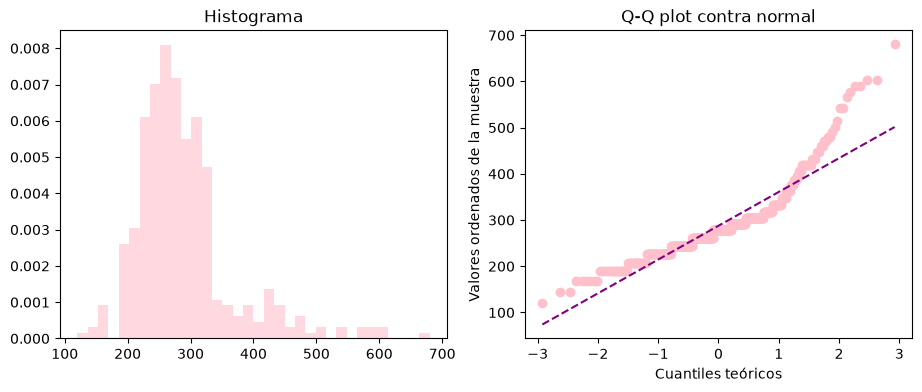

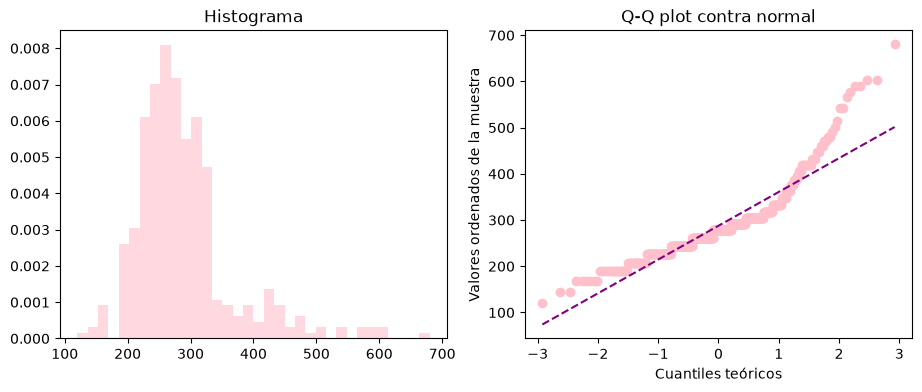

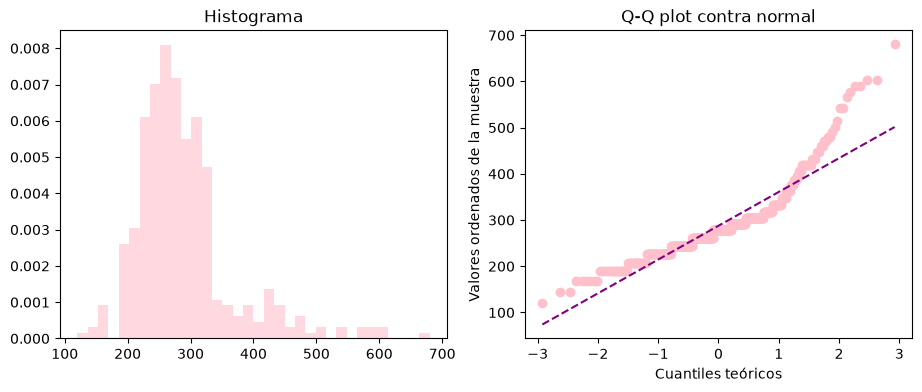

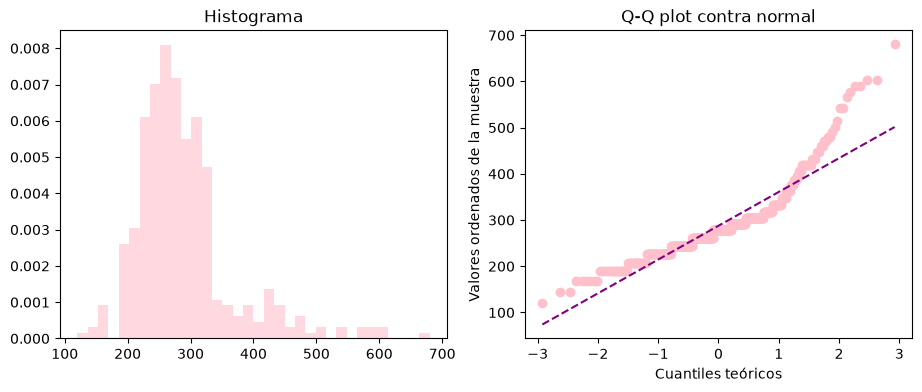

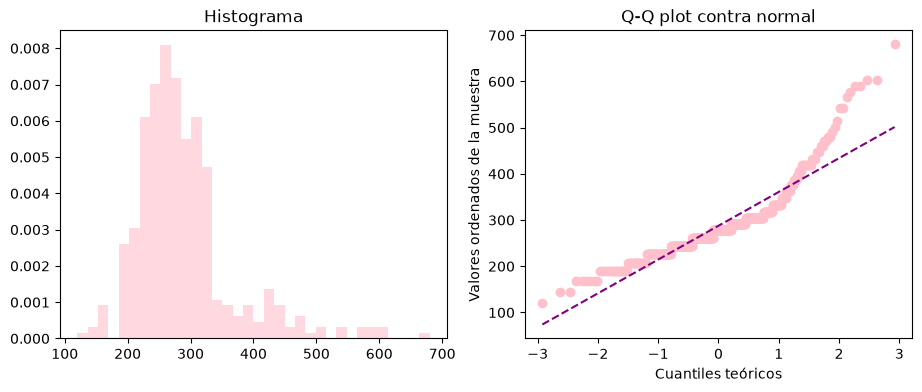

In [23]:
for c in cols:
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))

    ax[0].hist(x, bins="auto", color = "pink", label= c, density=True, alpha=0.6)
    ax[0].set_title("Histograma")

    scipy.stats.probplot(x, dist="norm", plot=ax[1])
    ax[1].set_title("Q-Q plot contra normal")
    ax[1].set_xlabel("Cuantiles teóricos")
    ax[1].set_ylabel("Valores ordenados de la muestra")
    markers = ax[1].get_lines()[0]
    markers.set_markerfacecolor('pink')
    markers.set_markeredgecolor('pink')
    fit_line = ax[1].get_lines()[1]
    fit_line.set_color('purple')
    fit_line.set_linestyle('--')

    plt.savefig("../results/t2_p1_Q-Q_" + c + ".png")
    plt.show()

A partir de los diagramas Q-Q, podemos observar que ninguna distribución se mantiene totalmente cerca de la recta ( en morado), por lo que ninguna de ellas sigue exactamente una ley normal. Aún así y usando además los datos de la tabla, quienes mas se asemejan a esta ley son los puntajes NEM y ranking, mientras que el resto de puntajes no se asemeja mucho. 

Con KDE

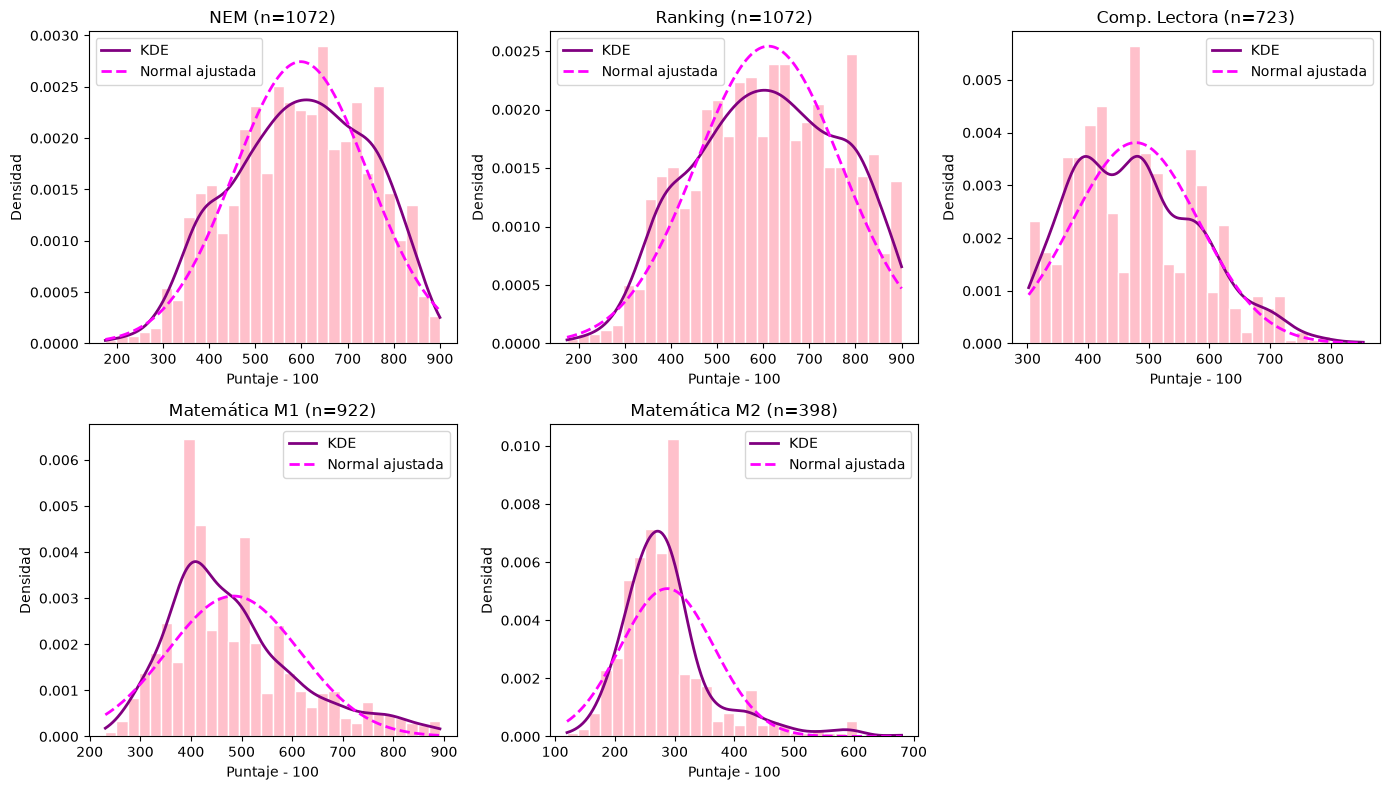

In [2]:
#Los datos ya están desplazados en 100 puntos menos, como la recomendación del enunciado.

df = pd.read_csv("../data/precessed/colegios_independencia_PAES2025_desplazados.csv")

cols = ["PTJE_NEM", "PTJE_RANKING", "CLEC_REG_ACTUAL",
        "MATE1_REG_ACTUAL", "MATE2_REG_ACTUAL"]
nombres = ["NEM", "Ranking", "Comp. Lectora", "Matemática M1", "Matemática M2"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for ax, c, nombre in zip(axes, cols, nombres):
    x = df[c].dropna()
    grid = np.linspace(x.min(), x.max(), 400)

    ax.hist(x, bins=30, edgecolor="white", color="pink", density=True)

    # KDE (naranja)
    ax.plot(grid, st.gaussian_kde(x)(grid), color="purple", lw=2, label="KDE")

    # Normal ajustada (verde punteada)
    ax.plot(grid, st.norm.pdf(grid, loc=x.mean(), scale=x.std(ddof=1)),
            "--", color="fuchsia", lw=2, label="Normal ajustada")

    ax.set_title(f"{nombre} (n={len(x)})")
    ax.set_xlabel("Puntaje - 100")
    ax.set_ylabel("Densidad")
    ax.legend()

axes[-1].axis("off")
plt.tight_layout()
plt.savefig("../results/t2_p1_histogramas.png", dpi=150)
plt.show()

Están los histogramas de cada prueba, además de un KDE para ver la densidad estimada en cada intervalo y una normal ajustada a la media y varianza de los datos.

Definitivamente no tienen la misma distribucion, las de nem y ranking son muy achatadas y están hacia la derecha. El resto tiene sus peaks más hacia la izquierda, y luego una cola de baja densidad hacia la derecha. Podemos notar peaks marcados en las pruebas de matemáticas, mientras que en lenguaje vemos que se encuentran varios intervalos con una densidad alta.

Se puede observar que competencia lectora sigue una distribución multimodal, a diferencia de M1, que presenta una única moda. 
Ambas distribuciones tienen una asimetría importante, por lo que podemos descartar normalidad. 

Intervalos de Confianza <br>
Supondemos que MATE1_REG_ACTUAL son una M.A.S. $X_i\sim \text{Lognormal}(\mu, \sigma^2)$


Grafiquemos el histograma de las $Z_i=\ln (X_i)$, $z_i=\ln (x_i)$.

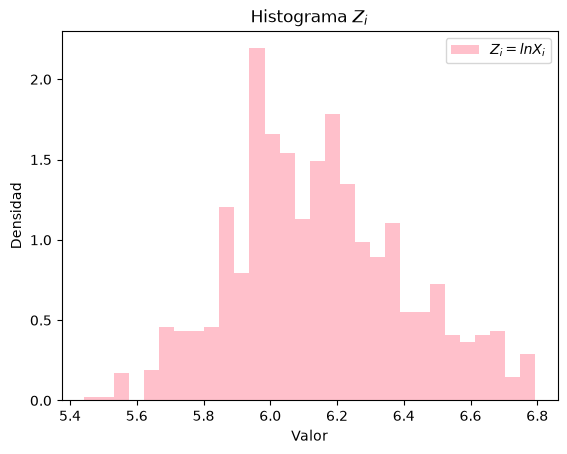

In [7]:
df = pd.read_csv("../data/precessed/colegios_independencia_PAES2025_desplazados.csv")

plt.hist( np.log(df["MATE1_REG_ACTUAL"]), bins=30, color="pink",label="$Z_i= ln X_i$",density=True)
plt.xlabel("Valor")
plt.ylabel("Densidad")
plt.title("Histograma $Z_i$")
plt.legend()
plt.savefig("../results/t2_p1_histograma_Z_i.png")
plt.show()

Y frente a una normal teorica con la misma media y desviación estandar

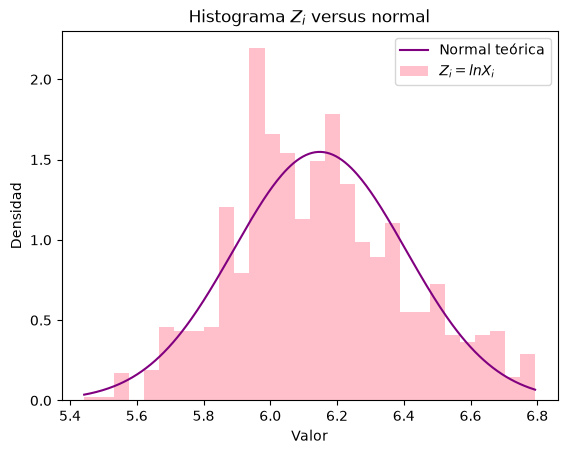

In [9]:
x = np.linspace(np.log(df["MATE1_REG_ACTUAL"]).min(), np.log(df["MATE1_REG_ACTUAL"]).max(), 300)  

plt.plot(x, scipy.stats.norm.pdf(x, loc=np.log(df["MATE1_REG_ACTUAL"]).mean() , scale=np.log(df["MATE1_REG_ACTUAL"]).std()), color="purple", label="Normal teórica") 
plt.hist( np.log(df["MATE1_REG_ACTUAL"]), bins =30 , color="pink", density=True, label="$Z_i= ln X_i$") 
plt.xlabel("Valor") 
plt.ylabel("Densidad") 
plt.title("Histograma $Z_i$ versus normal") 
plt.legend() 
plt.savefig("../results/t2_p1_histograma_Z_i_vs_normal.png") 
plt.show()

hagamos un diagrama q-q para comparar con la lognormal (para los $x_i$)

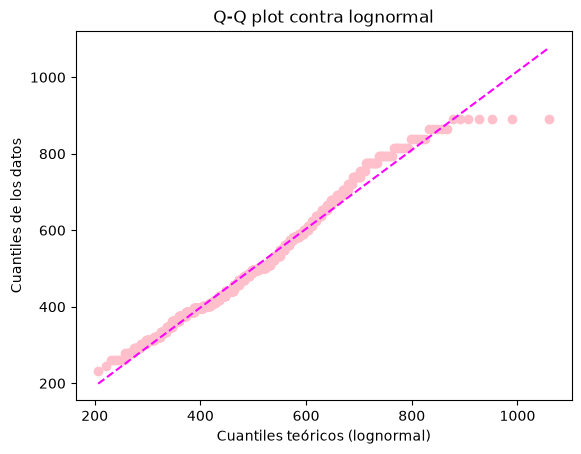

In [30]:
y = df["MATE1_REG_ACTUAL"]
y = y[~np.isnan(y)]

fig, ax = plt.subplots()

s, loc, scale = scipy.stats.lognorm.fit(y, floc=0)

scipy.stats.probplot(y, dist=scipy.stats.lognorm, sparams=(s, loc, scale), plot=plt)
plt.title("Q-Q plot contra lognormal")
plt.xlabel("Cuantiles teóricos (lognormal)")
plt.ylabel("Cuantiles de los datos")
markers = ax.get_lines()[0]
markers.set_markerfacecolor('pink')
markers.set_markeredgecolor('pink')
fit_line = ax.get_lines()[1]
fit_line.set_color("fuchsia")
fit_line.set_linestyle('--')
plt.show()

Podemos ver que los puntos se asemejan mucho a la recta, lo que nos indica que sigue una distribución muy similar a una lognormal.

Nos piden discutir propiedades del estimador propuesto, ver sesgo, consistencia, normalidad asintotica

Tenemos el estimador $\hat{\theta}_n = \exp(\bar{Z}+\frac{S^2_Z}{2})$.

In [5]:
#definimos las funciones pedidas


#método 1
def asintotico(x, alpha):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)] #filtramos los datos vacíos
    z = np.log(x)
    n = len(z)
    zbar = z.mean()
    s2 = z.var(ddof=1)
    Tn = np.exp(zbar + s2 / 2)
    Vn = Tn**2 * (s2 + s2**2 / 2)
    cuantil = st.norm.ppf(1 - alpha / 2)
    err = cuantil * np.sqrt(Vn / n)
    return (Tn - err, Tn + err)

#método 2
def cox(x, alpha):
    x = np.asarray(x, dtype=float); x = x[~np.isnan(x)]
    z = np.log(x); n = len(z)
    zbar, s2 = z.mean(), z.var(ddof=1)
    scap = np.sqrt(s2/n + s2**2/(2*(n-1)))
    cuantil = st.norm.ppf(1 - alpha/2)
    a = zbar + s2/2
    return (np.exp(a - cuantil*scap), np.exp(a + cuantil*scap))


#método 3
def gci(x, alpha, m=1000, semilla=223):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    z = np.log(x)
    n = len(z)

    # Paso 1: estadísticos de los datos
    zbar = z.mean()
    s2 = z.var(ddof=1)
    s = np.sqrt(s2)

    # Paso 2 y 3: simular m veces
    rng = np.random.default_rng(semilla)
    epsilon = rng.standard_normal(m)              
    U2 = rng.chisquare(df=n - 1, size=m)       
    U = np.sqrt(U2)

    T = np.exp(zbar
               - epsilon / (U / np.sqrt(n - 1)) * (s / np.sqrt(n))
               + s2 / (2 * U2 / (n - 1)))

    # Paso 4: ordenar y tomar los cuantiles alpha/2 y 1-alpha/2
    T = np.sort(T)
    inf = T[int(np.floor(m * alpha / 2))]
    sup = T[min(int(np.ceil(m * (1 - alpha / 2))) - 1, m - 1)]
    return (inf, sup)

In [6]:
df = pd.read_csv("../data/precessed/colegios_independencia_PAES2025_desplazados.csv")
m1 = df["MATE1_REG_ACTUAL"].dropna()

metodos = {"Asintótico": asintotico, "Cox": cox, "GCI": gci}

def tabla_ic(x, alpha): #construimos diccionarios gaurdando los datos de usar cada metodo
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    filas = []
    for nombre, f in metodos.items():
        inf, sup = f(x, alpha)
        filas.append({"método": nombre, "alpha": alpha, "n": len(x),
                      "inf": inf, "sup": sup, "largo": sup - inf})
    return pd.DataFrame(filas)


#Variar alpha
t_todos = pd.concat([tabla_ic(m1, alpha) for alpha in [0.10, 0.05, 0.01]], ignore_index=True)
print(t_todos.round(2))
t_todos.to_csv("../results/t2_p1_ic_todos.csv", index=False)

#alpha = 0.05, estudiaremos grupos distintos (tipo de establecimiento, colegios, modalidad)
grupos = {}
for k, g in df.groupby("TIPO_ESTABLECIMIENTO"): grupos[f"Tipo: {k}"] = g["MATE1_REG_ACTUAL"]
for k, g in df.groupby("MODALIDAD"):            grupos[f"Modalidad: {k}"] = g["MATE1_REG_ACTUAL"]
cnt = df.groupby("NOMBRE_COLEGIO")["MATE1_REG_ACTUAL"].count()
for k in cnt[cnt >= 5].index:                 
    grupos[f"Colegio: {k}"] = df.loc[df.NOMBRE_COLEGIO == k, "MATE1_REG_ACTUAL"]

t_grupos = pd.concat([tabla_ic(x.dropna(), 0.05).assign(grupo=nombre)
                      for nombre, x in grupos.items() if x.notna().sum() >= 5],
                     ignore_index=True)
print(t_grupos.round(1).to_string())
t_grupos.to_csv("../results/t2_p1_ic_grupos.csv", index=False)



       método  alpha    n     inf     sup  largo
0  Asintótico   0.10  922  476.82  490.55  13.73
1         Cox   0.10  922  476.87  490.60  13.73
2         GCI   0.10  922  477.06  490.66  13.60
3  Asintótico   0.05  922  475.51  491.86  16.36
4         Cox   0.05  922  475.58  491.93  16.36
5         GCI   0.05  922  475.95  491.66  15.72
6  Asintótico   0.01  922  472.94  494.43  21.50
7         Cox   0.01  922  473.05  494.56  21.50
8         GCI   0.01  922  473.88  494.50  20.61
        método  alpha    n    inf    sup  largo                                                            grupo
0   Asintótico    0.0  227  440.2  467.4   27.1                                                  Tipo: Municipal
1          Cox    0.0  227  440.4  467.6   27.1                                                  Tipo: Municipal
2          GCI    0.0  227  441.2  467.3   26.1                                                  Tipo: Municipal
3   Asintótico    0.0   81  514.2  582.4   68.2           

se puede observar que para todos los valores de alpha, el largo de los intervalos de los métodos asintotico y cox fue el mismo, y fue mayor al largo de los intervalos para el metodo de los intervalos de confianza generalizados. 